# Import Packages

In [11]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns


from libpysal.weights import DistanceBand
from esda.moran import Moran
from splot.esda import moran_scatterplot

# Import Data

In [12]:
df = pd.read_csv("../outputs/inla-spde_residuals_full.csv")
df['tanggal'] = pd.to_datetime(df['tanggal'])

df.head()

,tanggal,stasiun,pm25,pm10,so2,co,o3,no2,max,critical,...,ssrd,tp_mm,pred_xgb,residual,dataset_type,residual_train,spde_fitted,iid_fitted,stasiun_id,bym2_fitted
0,2023-01-01,DKI1 (Bunderan HI),55.0,44.0,47.0,10.0,24.0,9.0,55.0,PM25,...,16794192,21.383282,52.110920,2.889080,train,2.889080,-0.983305,-1.158467,1,-0.703893
1,2023-01-02,DKI1 (Bunderan HI),43.0,32.0,52.0,9.0,24.0,8.0,52.0,SO2,...,19450636,5.191999,50.737793,-7.737793,train,-7.737793,-0.983305,-1.158467,1,-0.703893
2,2023-01-03,DKI1 (Bunderan HI),35.0,31.0,49.0,9.0,12.0,7.0,49.0,SO2,...,14011936,20.043148,41.951580,-6.951580,train,-6.951580,-0.983305,-1.158467,1,-0.703893
3,2023-01-04,DKI1 (Bunderan HI),47.0,30.0,53.0,11.0,15.0,9.0,53.0,SO2,...,25899534,10.425209,42.369755,4.630245,train,4.630245,-0.983305,-1.158467,1,-0.703893
4,2023-01-05,DKI1 (Bunderan HI),50.0,38.0,50.0,13.0,26.0,11.0,50.0,PM25,...,19027820,1.566000,51.808403,-1.808403,train,-1.808403,-0.983305,-1.158467,1,-0.703893


In [13]:
df_test = df[df['dataset_type'] == 'test'].copy()

## Residual pada Data Testing

- Residual yang digunakan pada tahap diagnostik merupakan residual dari data testing, yaitu selisih antara nilai aktual PM2.5 dan hasil prediksi model pada periode awal tahun 2025.

- Penggunaan residual data testing dilakukan karena residual pada data ini merepresentasikan performa model terhadap observasi yang benar-benar belum pernah dilihat sebelumnya (*out-of-sample residual*).

- Dengan demikian, analisis residual menjadi lebih representatif untuk mengevaluasi kemampuan generalisasi model dalam kondisi aktual.

- Residual dari data training tidak digunakan sebagai fokus utama diagnostik karena model telah belajar langsung dari data tersebut sehingga berpotensi menghasilkan evaluasi yang terlalu optimistis.

- Pendekatan ini membantu memastikan bahwa pola residual yang dianalisis benar

# Residual Distribution

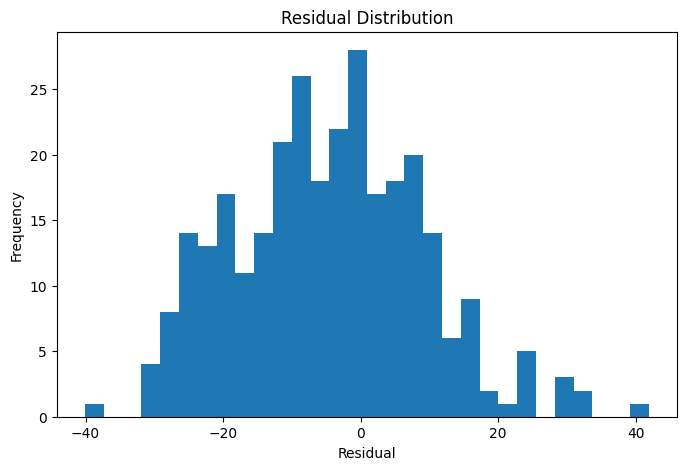

In [14]:
plt.figure(figsize=(8,5))

plt.hist(
    df_test['residual'],
    bins=30
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Residual Distribution")

plt.show()

## Distribusi Residual

- Berdasarkan histogram, sebagian besar residual terpusat di sekitar nilai nol, yang menunjukkan bahwa model XGBoost secara umum mampu menghasilkan prediksi yang cukup dekat dengan nilai aktual PM2.5.

- Distribusi residual terlihat relatif menyerupai bentuk lonceng (*approximately normal*), meskipun masih terdapat sedikit kemencengan dan beberapa residual ekstrem pada sisi kanan distribusi.

- Adanya residual positif yang cukup besar menunjukkan bahwa pada beberapa observasi model masih mengalami *underprediction*, yaitu nilai aktual PM2.5 lebih tinggi dibanding hasil prediksi model.

- Secara umum, histogram menunjukkan bahwa model telah menangkap sebagian besar pola utama PM2.5, namun masih terdapat variasi tertentu yang belum sepenuhnya dijelaskan oleh model.

# Residual vs Prediction 

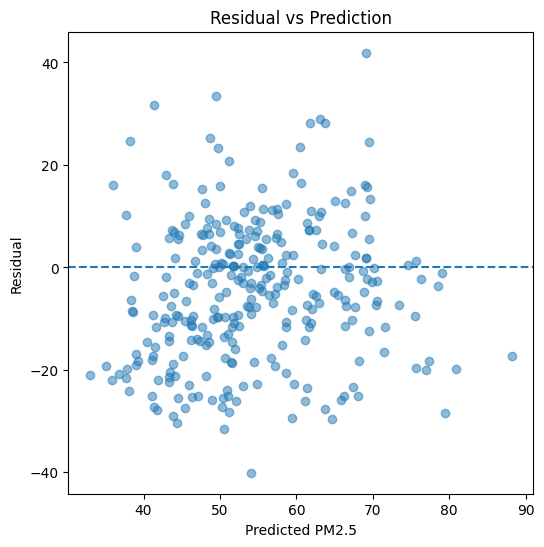

In [15]:
plt.figure(figsize=(6,6))

plt.scatter(
    df_test['pred_xgb'],
    df_test['residual'],
    alpha=0.5
)

plt.axhline(
    0,
    linestyle='--'
)

plt.xlabel("Predicted PM2.5")
plt.ylabel("Residual")

plt.title("Residual vs Prediction")

plt.show()

## Residual vs Prediction

- Scatter plot residual terhadap nilai prediksi digunakan untuk mengevaluasi pola kesalahan model terhadap hasil prediksi PM2.5.

- Pada model yang baik, residual diharapkan menyebar secara acak di sekitar garis nol tanpa membentuk pola tertentu.

- Berdasarkan visualisasi, residual terlihat cukup menyebar di sekitar garis nol, yang menunjukkan bahwa model XGBoost telah mampu menangkap sebagian besar pola utama pada data PM2.5.

- Tidak terlihat pola non-linear yang sangat jelas, sehingga hubungan antara prediksi dan residual relatif stabil.

- Namun, masih terdapat beberapa residual ekstrem baik positif maupun negatif yang menunjukkan adanya observasi tertentu yang belum dapat diprediksi secara optimal oleh model.

- Sebaran residual juga tampak sedikit lebih lebar pada rentang prediksi tertentu, yang mengindikasikan kemungkinan adanya variansi error yang tidak sepenuhnya konstan (*mild heteroskedasticity*).

- Secara umum, plot residual vs prediction menunjukkan bahwa model memiliki performa yang cukup baik, meskipun masih terdapat variasi lokal dan fluktuasi PM2.5 yang belum sepenuhnya terakomodasi.

# Mean Residual by Station

In [16]:
station_resid = (
    df_test.groupby('stasiun')
    .agg({
        'lon': 'first',
        'lat': 'first',
        'residual': 'mean'
    })
    .reset_index()
)

print(station_resid)

                stasiun       lon       lat   residual
0    DKI1 (Bunderan HI)  106.8235 -6.194660  -1.713154
1  DKI2 (Kelapa Gading)  106.9109 -6.153570  -3.112886
2      DKI3 (Jagakarsa)  106.8037 -6.356930   0.927357
3   DKI4 (Lubang Buaya)  106.9092 -6.288890 -18.503244
4    DKI5 (Kebon Jeruk)  106.7526 -6.207255  -0.723736


## Rata-Rata Residual Berdasarkan Stasiun

### Interpretasi Tanda

- Analisis rata-rata residual per stasiun dilakukan untuk melihat apakah terdapat bias prediksi yang berbeda pada masing-masing lokasi pengamatan.

- Nilai residual negatif menunjukkan bahwa model cenderung melakukan *overprediction*, yaitu hasil prediksi lebih tinggi dibanding nilai aktual.

- Sebaliknya, residual positif menunjukkan kecenderungan *underprediction*, yaitu model memprediksi PM2.5 lebih rendah dibanding kondisi aktual.

---

### Interpretasi Nilai per Stasiun

- `DKI4 (Lubang Buaya)` memiliki residual rata-rata paling negatif (`-18.68`), menunjukkan bahwa model cukup sering melakukan overprediction pada stasiun ini.

- `DKI2 (Kelapa Gading)` juga menunjukkan kecenderungan overprediction, meskipun tidak sebesar DKI4.

- `DKI1 (Bunderan HI)` memiliki residual mendekati nol, yang menunjukkan bahwa performa model pada lokasi ini relatif seimbang dan stabil.

- `DKI5 (Kebon Jeruk)` dan `DKI3 (Jagakarsa)` memiliki residual positif, sehingga model cenderung sedikit underpredict pada kedua stasiun tersebut.

---

### Kesimpulan

- Perbedaan rata-rata residual antar stasiun mengindikasikan bahwa masih terdapat variasi spasial yang belum sepenuhnya dijelaskan oleh model XGBoost.

- Hasil ini menjadi indikasi awal adanya *localized station-specific effects* atau struktur spasial residual yang dapat dianalisis lebih lanjut menggunakan pendekatan Bayesian spatial modeling.

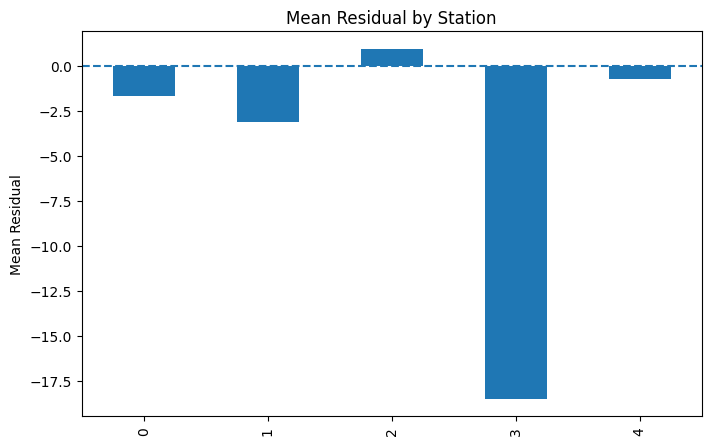

In [17]:
plt.figure(figsize=(8,5))

station_resid["residual"].plot(kind='bar')

plt.axhline(
    0,
    linestyle='--'
)

plt.ylabel("Mean Residual")

plt.title("Mean Residual by Station")

plt.show()

# Moran's I

In [18]:
coords = station_resid[['lon', 'lat']].values

w = DistanceBand(
    coords,
    threshold=0.2,
    binary=True,
    silence_warnings=True
)

w.transform = 'R'

y = station_resid['residual'].values

moran = Moran(y, w)

print("Moran's I :", moran.I)
print("p-value   :", moran.p_sim)

Moran's I : -0.28350809986830855
p-value   : 0.315


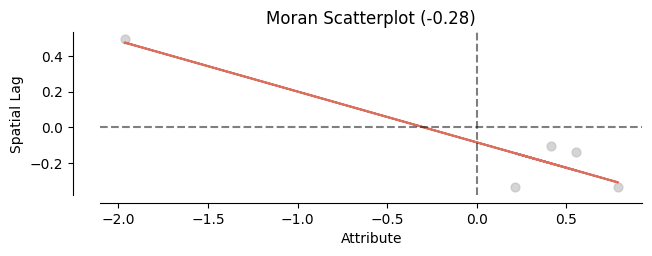

In [19]:
fig, ax = moran_scatterplot(moran)

plt.show()

## Moran’s I Residual Analysis


### Interpretasi Moran’s I

- Moran’s I digunakan untuk menguji ada tidaknya autokorelasi spasial pada residual model.

- Nilai Moran’s I sebesar `-0.257` menunjukkan kecenderungan autokorelasi spasial negatif yang lemah pada residual.

- Namun, nilai `p-value = 0.398` menunjukkan bahwa hasil tersebut tidak signifikan secara statistik, sehingga tidak terdapat bukti kuat adanya pola spasial global pada residual.

- Dengan kata lain, residual model XGBoost cenderung tidak membentuk clustering spasial yang jelas antar stasiun pengamatan.

---

### Mengapa Moran’s I Kurang Kuat pada Kasus Ini

- Jumlah stasiun pengamatan relatif sangat sedikit, sehingga kekuatan uji statistik Moran’s I menjadi terbatas.

- Moran’s I lebih efektif digunakan pada data dengan jumlah lokasi spasial yang cukup banyak dan distribusi wilayah yang lebih rapat.

- Pada kasus ini, hanya terdapat beberapa titik stasiun pemantauan sehingga:
  - hubungan ketetanggaan menjadi sangat terbatas,
  - estimasi autokorelasi spasial menjadi kurang stabil,
  - dan sensitivitas uji terhadap pola spasial lokal menjadi rendah.

- Selain itu, Moran’s I terutama mendeteksi pola spasial global (*global spatial autocorrelation*), sehingga pola spasial lokal atau efek spasial halus (*localized spatial effects*) dapat saja tidak terdeteksi secara signifikan.

- Residual PM2.5 juga berpotensi dipengaruhi oleh:
  - karakteristik lingkungan lokal,
  - kepadatan lalu lintas,
  - sumber emisi sekitar stasiun,
  - serta dinamika atmosfer mikro,
  
  yang tidak selalu membentuk pola spasial global yang kuat.

---

### Justifikasi Melanjutkan ke INLA-SPDE

- Meskipun Moran’s I tidak signifikan, analisis residual sebelumnya menunjukkan adanya perbedaan rata-rata residual antar stasiun.

- Hal tersebut mengindikasikan bahwa masih terdapat variasi spasial tertentu yang belum sepenuhnya dijelaskan oleh model XGBoost.

- Oleh karena itu, analisis dilanjutkan menggunakan pendekatan Bayesian spatial modeling melalui INLA-SPDE untuk menangkap:
  - latent spatial effect,
  - smooth spatial surface,
  - dan dependensi spasial kontinu yang mungkin tidak terdeteksi oleh Moran’s I.

- Pendekatan SPDE lebih fleksibel karena tidak hanya bergantung pada struktur ketetanggaan diskret, tetapi memodelkan proses spasial sebagai medan kontinu (*continuous spatial field*).

- Dengan demikian, INLA-SPDE tetap relevan digunakan untuk mengevaluasi kemungkinan adanya pola spasial residual yang bersifat halus dan lokal (*smooth latent spatial effects*), meskipun autokorelasi spasial global tidak signifikan.